<a href="https://colab.research.google.com/github/nevita275/PCVK26_20_Triya/blob/main/Week_9_20_Triya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20
<br>

# WEEK 9 <br><br>

## 1. Import folder yang ada di Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import beberapa library

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

## 3. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari openCV

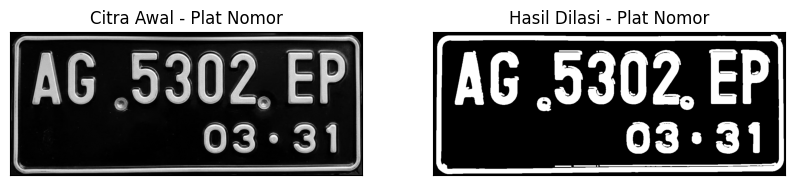

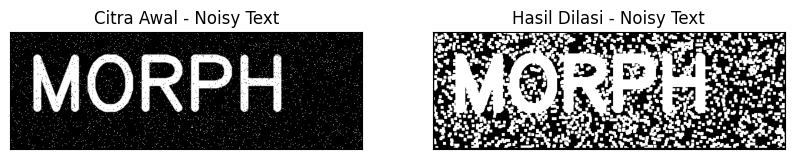

In [3]:
# Dilasi tanpa library OpenCV

def dilasi_citra(F, w):
    # Size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# ==========================================
# GAMBAR 1: PLAT NOMOR
# ==========================================

img_d = cv2.imread(
    '/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0
)

ret, thresh = cv2.threshold(
    img_d, 125, 200, cv2.THRESH_BINARY
)

w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Hasil Dilasi - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# ==========================================
# GAMBAR 2: NOISY TEXT
# ==========================================

img_d2 = cv2.imread(
    '/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0
)

ret2, thresh2 = cv2.threshold(
    img_d2, 125, 200, cv2.THRESH_BINARY
)

w = 5
imgD2 = dilasi_citra(thresh2, w)

plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_d2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD2, cmap='gray')
plt.title('Hasil Dilasi - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED) berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


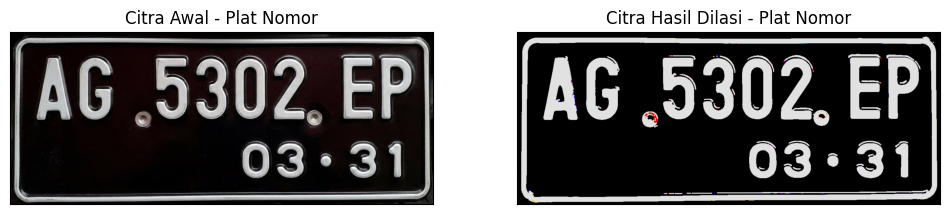

[[1 1 1]
 [1 1 1]
 [1 1 1]]


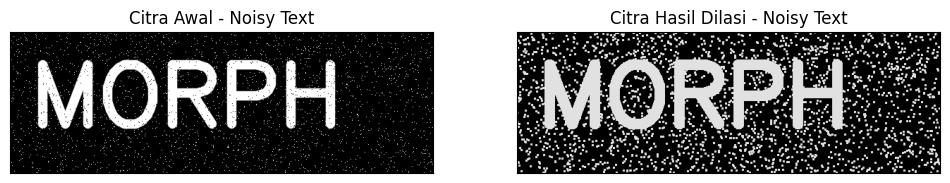

In [25]:
# GAMBAR 1: PLAT NOMOR
img = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg')

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)

print(kernel)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Dilasi - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png')

ret2, thresh2 = cv2.threshold(img2, 127, 225, cv2.THRESH_BINARY)

kernel2 = np.ones((3, 3), np.uint16)
dilasi2 = cv2.dilate(thresh2, kernel2, iterations=1)

print(kernel2)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(cv2.cvtColor(dilasi2, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Dilasi - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV

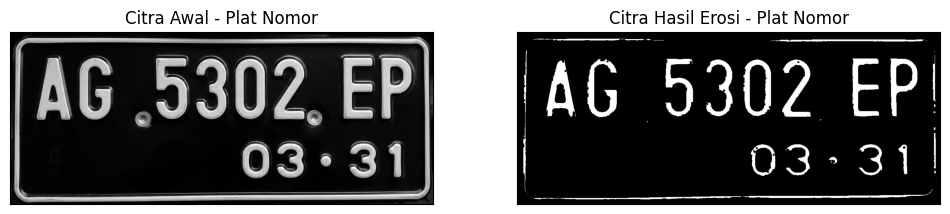

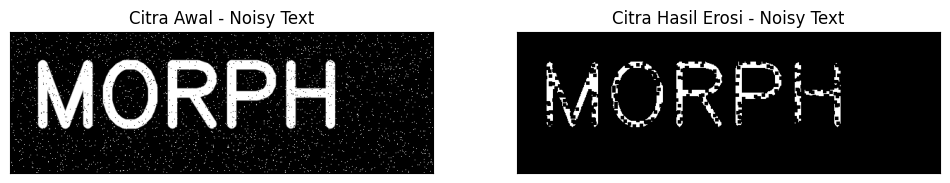

In [5]:
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# GAMBAR 1: PLAT NOMOR
img_e = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)

ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img_e2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)

ret2, thresh2 = cv2.threshold(img_e2, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE2 = erosi_citra(thresh2, k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_e2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE2, cmap='gray')
plt.title('Citra Hasil Erosi - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk square 5 x 5 dengan menggunakan library morphology dari openCV

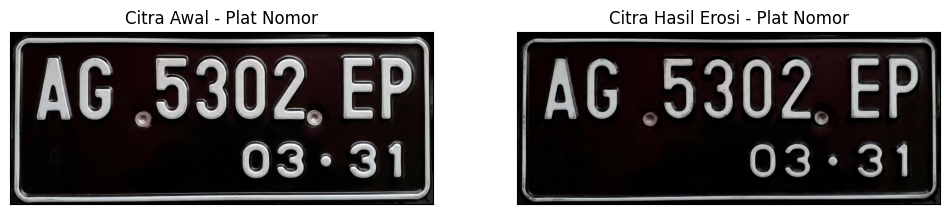

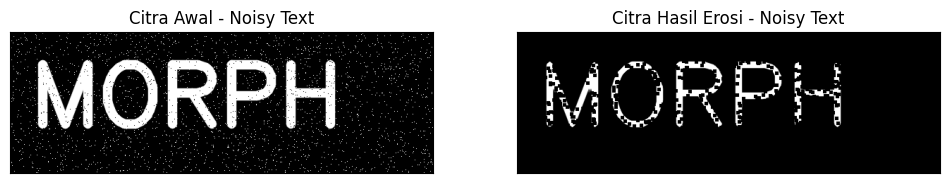

In [6]:
# GAMBAR 1: PLAT NOMOR
img = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg')

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Erosi - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png')

kernel2 = np.ones((5, 5), np.uint8)
erosion2 = cv2.erode(img2, kernel2, iterations=1)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(cv2.cvtColor(erosion2, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Erosi - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 7. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV

### 7A. Opening tanpa Library Morphology

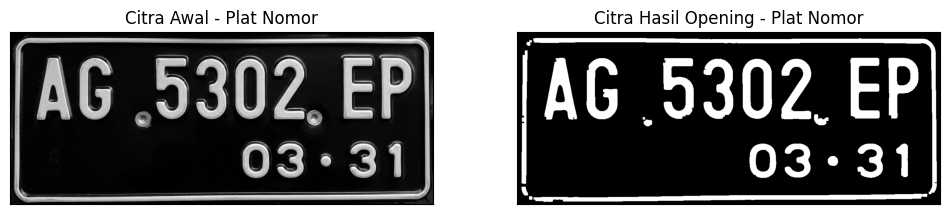

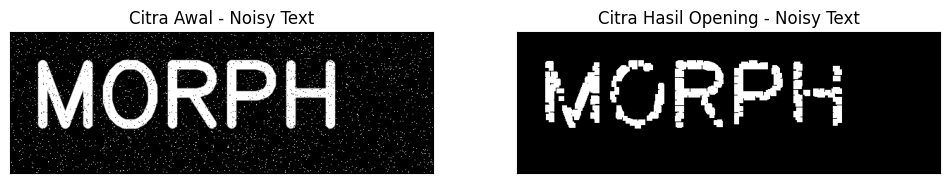

In [7]:
# GAMBAR 1: PLAT NOMOR
img_o = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)

reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img_o2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)

reto2, thresho2 = cv2.threshold(img_o2, 127, 225, cv2.THRESH_BINARY)

k = 7
imgO2 = dilasi_citra(erosi_citra(thresho2, k), k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_o2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgO2, cmap='gray')
plt.title('Citra Hasil Opening - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

### 7B. Opening menggunakan Library Morphology

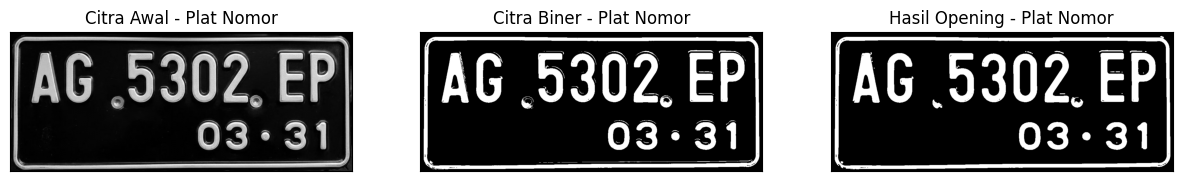

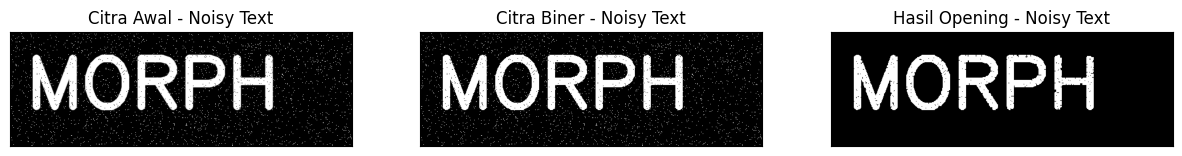

In [8]:
# GAMBAR 1: PLAT NOMOR
img = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(openn, cmap='gray')
plt.title('Hasil Opening - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)

ret2, thresh2 = cv2.threshold(img2, 127, 225, cv2.THRESH_BINARY)

kernel2 = np.ones((3, 3), np.uint8)
openn2 = cv2.morphologyEx(thresh2, cv2.MORPH_OPEN, kernel2)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh2, cmap='gray')
plt.title('Citra Biner - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(openn2, cmap='gray')
plt.title('Hasil Opening - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 8. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV
### 8A. Closing tanpa Library Morphology

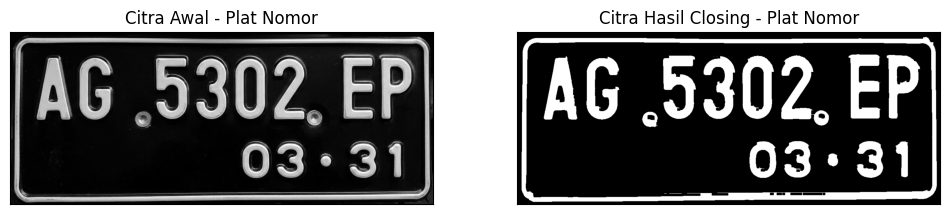

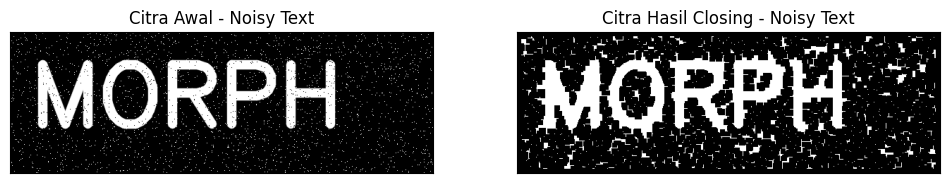

In [9]:
# GAMBAR 1: PLAT NOMOR
img_c = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)

retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img_c2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)

retc2, threshc2 = cv2.threshold(img_c2, 127, 225, cv2.THRESH_BINARY)

k = 7
imgC2 = erosi_citra(dilasi_citra(threshc2, k), k)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img_c2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgC2, cmap='gray')
plt.title('Citra Hasil Closing - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

### 8B. Closing menggunakan Library Morphology

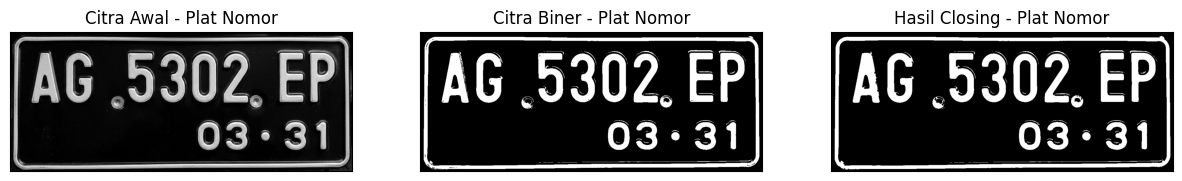

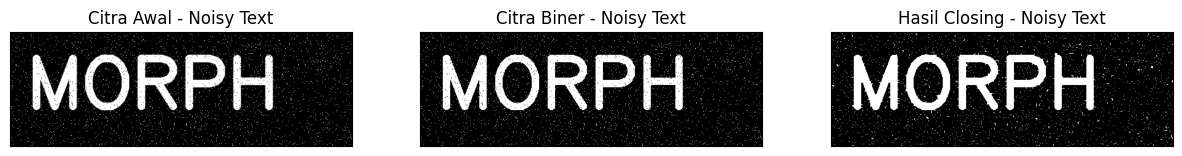

In [10]:
# GAMBAR 1: PLAT NOMOR
img = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(closs, cmap='gray')
plt.title('Hasil Closing - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


# GAMBAR 2: NOISY TEXT
img2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)

ret2, thresh2 = cv2.threshold(img2, 127, 225, cv2.THRESH_BINARY)

kernel2 = np.ones((3, 3), np.uint8)
closs2 = cv2.morphologyEx(thresh2, cv2.MORPH_CLOSE, kernel2)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh2, cmap='gray')
plt.title('Citra Biner - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(closs2, cmap='gray')
plt.title('Hasil Closing - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.show()

## 9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Cross 3 x 3 dan 5 x 5

### 9A. Cross 3 × 3

SED = Cross 3


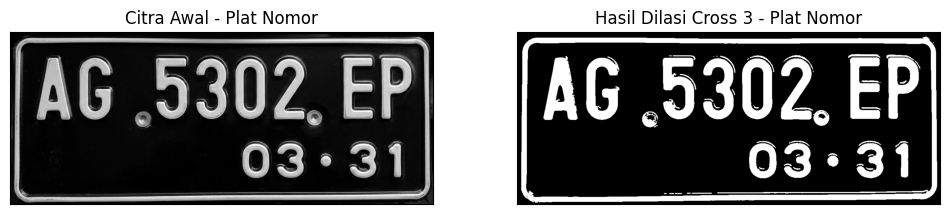

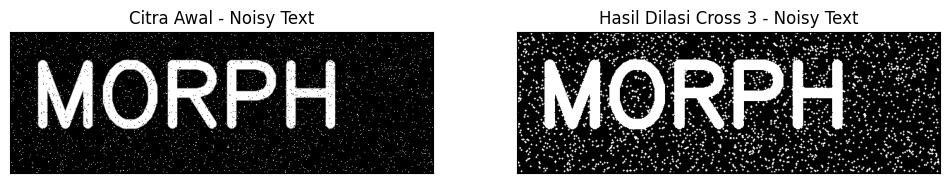

In [11]:
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Cross 3')

# GAMBAR 1: PLAT NOMOR
img_d = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Hasil Dilasi Cross 3 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_d2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_d2, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD2 = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD2, cmap='gray')
plt.title('Hasil Dilasi Cross 3 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()

### 9B. Cross 5 × 5

SED = Cross 5


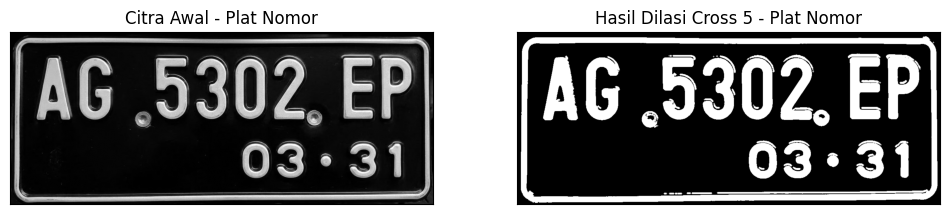

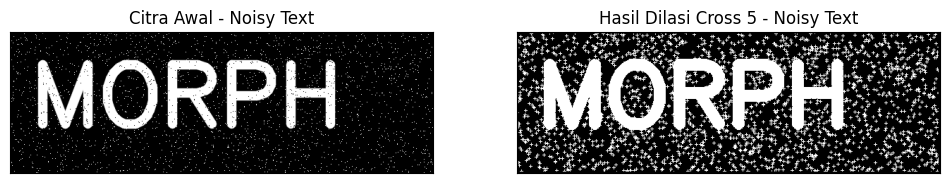

In [12]:
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.array([
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0],
        [1, 1, 1, 1, 1],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Cross 5')

# GAMBAR 1: PLAT NOMOR
img_d = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Hasil Dilasi Cross 5 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_d2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_d2, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD2 = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD2, cmap='gray')
plt.title('Hasil Dilasi Cross 5 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()

## 10. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Circular 3 x 3 dan 5 x 5

SED = Circle 3


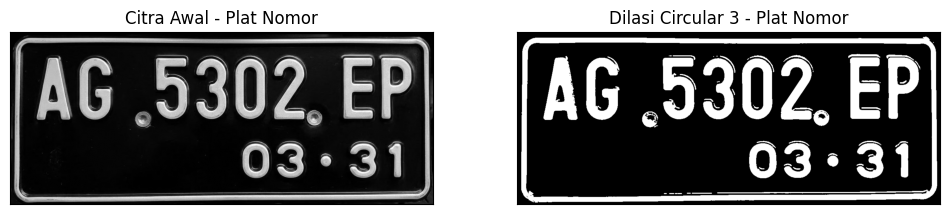

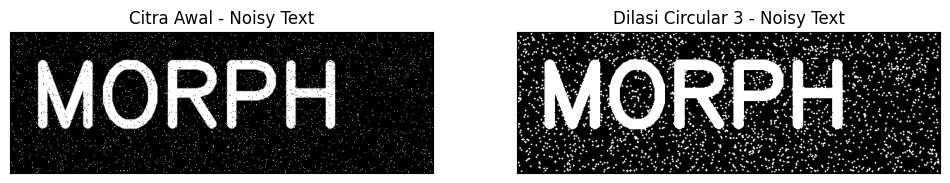

SED = Circle 5


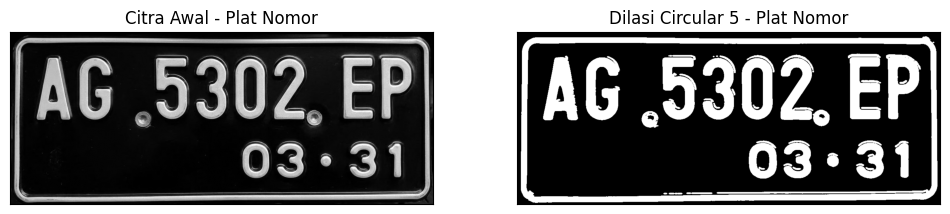

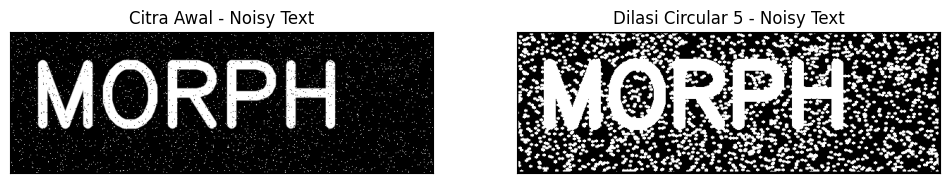

In [13]:
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# ==========================================
# CIRCULAR 3 x 3
# ==========================================

print('SED = Circle 3')

# GAMBAR 1: PLAT NOMOR
img_d = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Dilasi Circular 3 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_d2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_d2, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD2 = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD2, cmap='gray')
plt.title('Dilasi Circular 3 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()


# ==========================================
# CIRCULAR 5 x 5
# ==========================================

print('SED = Circle 5')

# GAMBAR 1: PLAT NOMOR
img_d = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Dilasi Circular 5 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_d2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_d2, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD2 = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_d2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgD2, cmap='gray')
plt.title('Dilasi Circular 5 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()

## 11. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7

SE = Rectangle 3x5


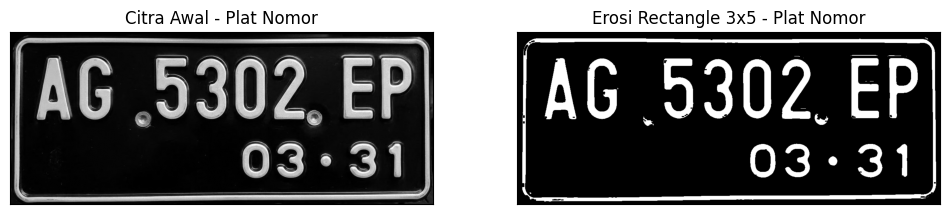

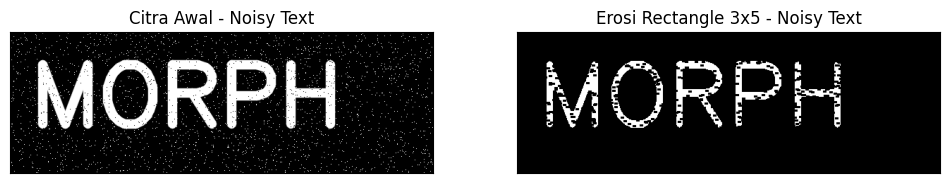

SE = Rectangle 5x7


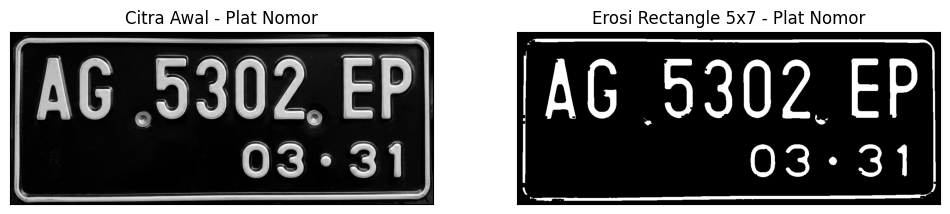

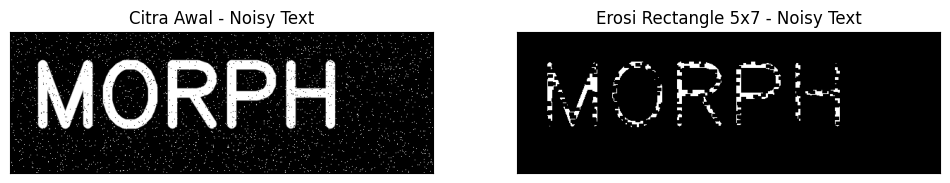

In [14]:
def erosi_citra(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    # Dimensi SE: tinggi = l, lebar = p
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant2:j+constant2+1
            ]

            # Perbaikan: dimensi temp harus sama dengan SE
            if temp.shape == SE.shape:
                product = temp * SE
                imgE[i, j] = np.min(product)

    return imgE


# ==========================================
# RECTANGLE 3 x 5
# ==========================================

print('SE = Rectangle 3x5')

# GAMBAR 1: PLAT NOMOR
img_e = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Rectangle 3x5 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_e2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_e2, 127, 225, cv2.THRESH_BINARY)

p = 5
l = 3
imgE2 = erosi_citra(thresh2, p, l)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE2, cmap='gray')
plt.title('Erosi Rectangle 3x5 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()


# ==========================================
# RECTANGLE 5 x 7
# ==========================================

print('SE = Rectangle 5x7')

# GAMBAR 1: PLAT NOMOR
img_e = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Rectangle 5x7 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_e2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_e2, 127, 225, cv2.THRESH_BINARY)

p = 7
l = 5
imgE2 = erosi_citra(thresh2, p, l)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE2, cmap='gray')
plt.title('Erosi Rectangle 5x7 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()

## 12. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Line Vertikal 3 dan 5

SE = Line Vertikal 3


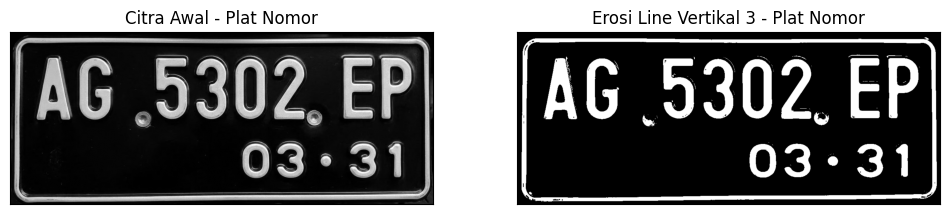

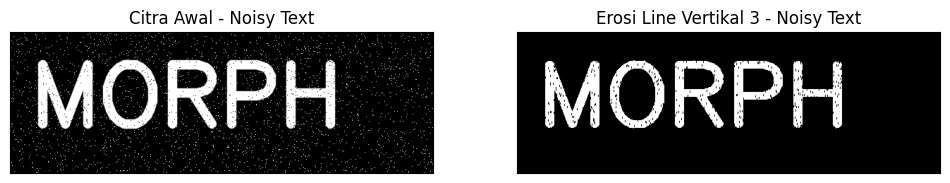

SE = Line Vertikal 5


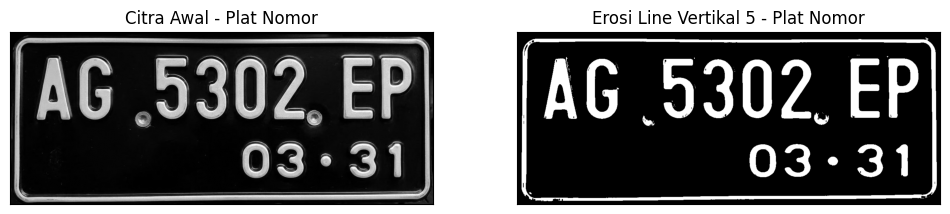

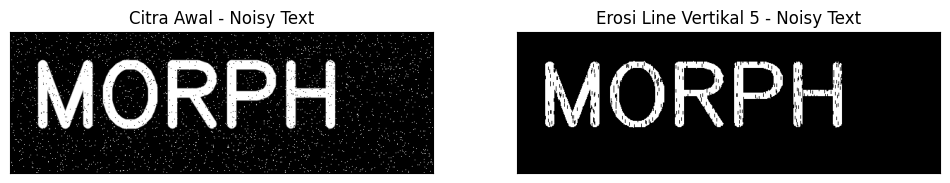

In [15]:
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(n):
            # Kernel (1, k) berarti tinggi k dan lebar 1
            temp = F[i-constant:i+constant+1, j:j+1]

            if temp.shape == SE.shape:
                product = temp * SE
                imgE[i, j] = np.min(product)

    return imgE


# ==========================================
# LINE VERTIKAL 3
# ==========================================

print('SE = Line Vertikal 3')

# GAMBAR 1: PLAT NOMOR
img_e = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 3
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Line Vertikal 3 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_e2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_e2, 127, 225, cv2.THRESH_BINARY)

k = 3
imgE2 = erosi_citra(thresh2, k)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE2, cmap='gray')
plt.title('Erosi Line Vertikal 3 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()


# ==========================================
# LINE VERTIKAL 5
# ==========================================

print('SE = Line Vertikal 5')

# GAMBAR 1: PLAT NOMOR
img_e = cv2.imread('/content/drive/MyDrive/PVCK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal - Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Line Vertikal 5 - Plat Nomor')
plt.xticks([])
plt.yticks([])
plt.show()


# GAMBAR 2: NOISY TEXT
img_e2 = cv2.imread('/content/drive/MyDrive/PVCK/Images/noisy_text.png', 0)
ret2, thresh2 = cv2.threshold(img_e2, 127, 225, cv2.THRESH_BINARY)

k = 5
imgE2 = erosi_citra(thresh2, k)

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.imshow(img_e2, cmap='gray')
plt.title('Citra Awal - Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(imgE2, cmap='gray')
plt.title('Erosi Line Vertikal 5 - Noisy Text')
plt.xticks([])
plt.yticks([])
plt.show()

## 13. Buatlah program transformasi Top-hat dengan structuring element 3 × 3

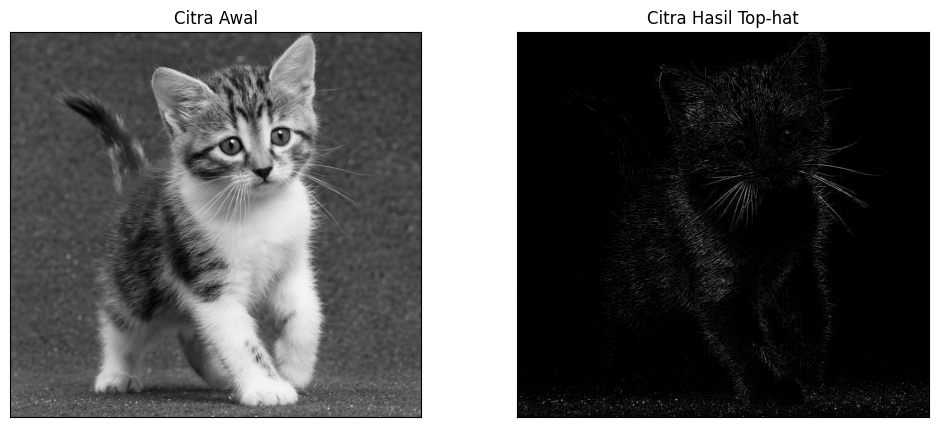

In [16]:
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Membaca gambar kitten01.jpg
img = cv2.imread(
    '/content/drive/MyDrive/PVCK/Images/kitten01.jpg'
)

# Mengubah gambar menjadi grayscale
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Menerapkan operasi Top-hat
tophat_img = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil Top-hat')
plt.xticks([])
plt.yticks([])

plt.show()

## 14. Buatlah program transformasi Black-hat dengan structuring element 3 × 3

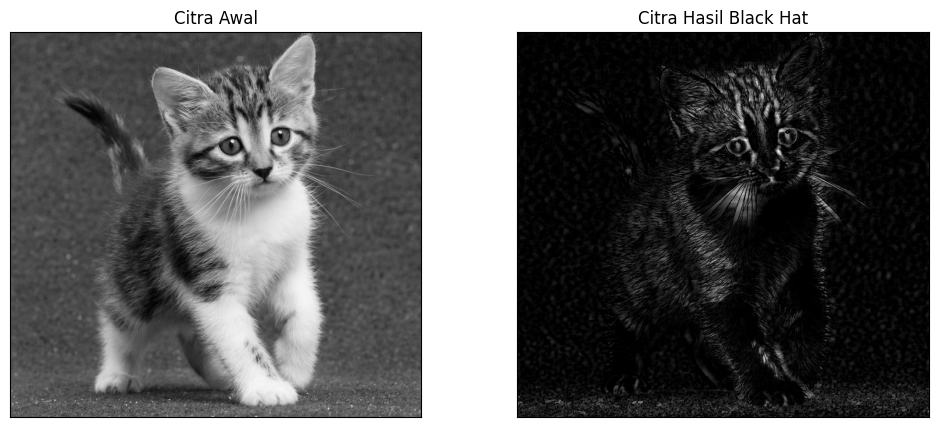

In [17]:
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Membaca gambar kitten01.jpg
img = cv2.imread(
    '/content/drive/MyDrive/PVCK/Images/kitten01.jpg'
)

# Mengubah gambar menjadi grayscale
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Membuat kernel sesuai kode aktif pada modul
Kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (13, 5)
)

# Menerapkan operasi Black-hat
blackhat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    Kernel
)

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat')
plt.xticks([])
plt.yticks([])

plt.show()

## 15. Buatlah program skeleton pada citra biner, lalu tampilkan citra biner dan rangkanya secara berdampingan

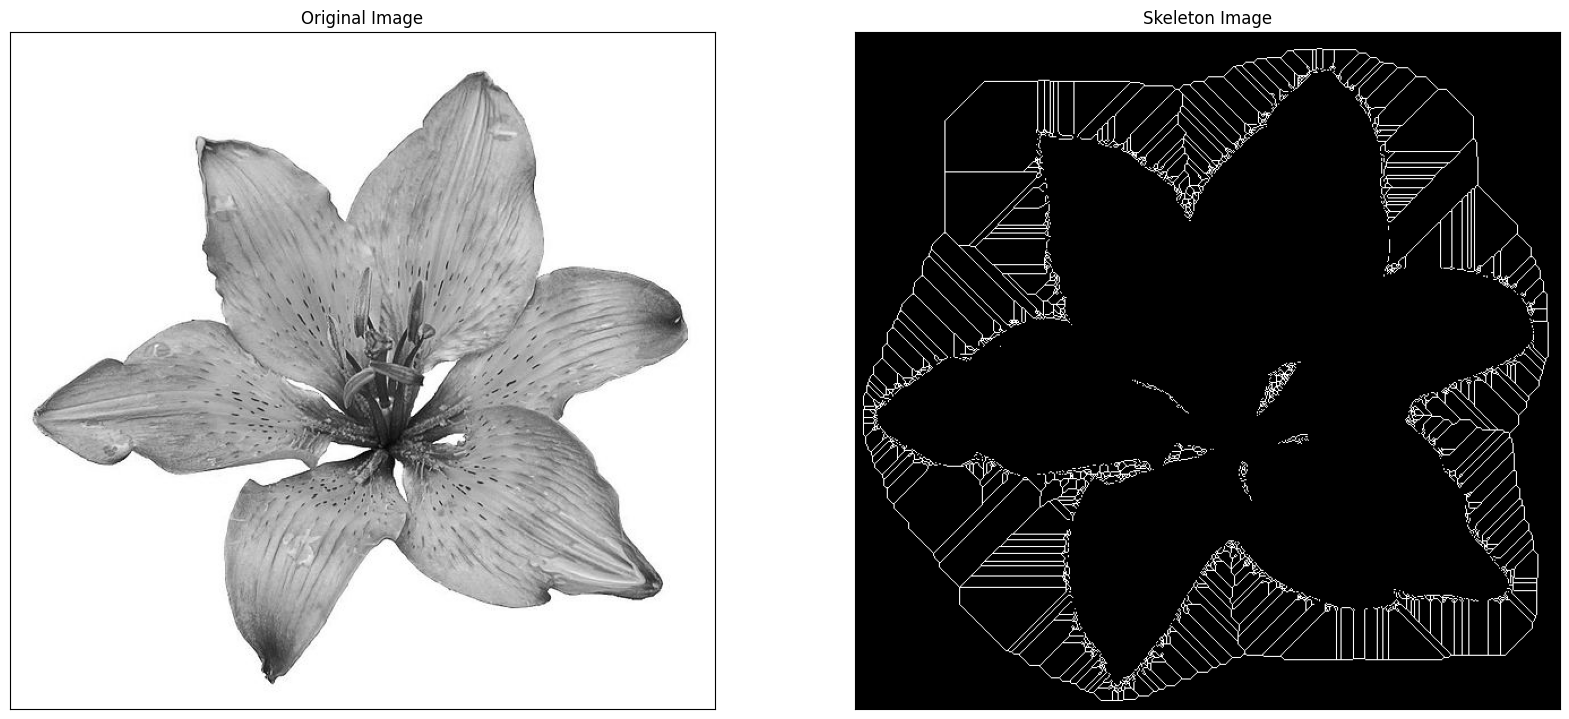

In [18]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Membaca gambar
img = cv.imread(
    '/content/drive/MyDrive/PVCK/Images/lily.jpg',
    0
)

# Membuat citra biner
binary = img > filters.threshold_triangle(img)

# Mengubah nilai True dan False menjadi 1 dan 0
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# Melakukan skeletonize
skeleton = skeletonize(binary_cp)

# Menampilkan gambar
plt.figure(figsize=(20, 20))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([])
plt.yticks([])

plt.savefig('binary and bin_skeleton.png')

plt.show()

## 16. Buatlah program skeleton pada citra hasil inversi, lalu bandingkan hasilnya dengan langkah sebelumnya

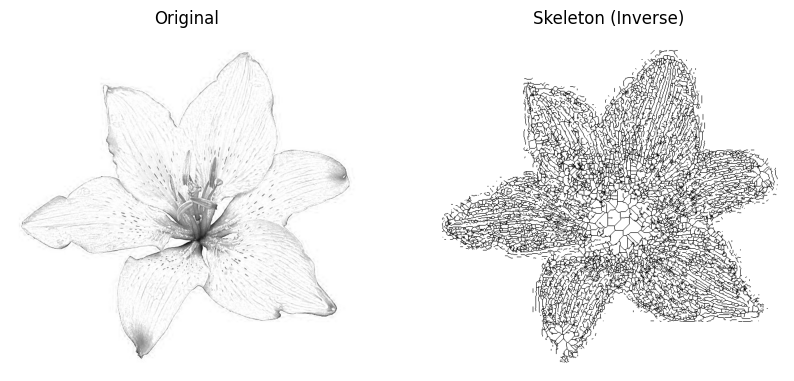

In [19]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Membaca gambar
img = io.imread(
    '/content/drive/MyDrive/PVCK/Images/lily.jpg'
)[..., 0]

# Membuat citra biner inversi
binary = img < filters.threshold_triangle(img)

# Melakukan skeletonize
skeleton = skeletonize(binary)

# Menampilkan gambar
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()

plt.show()

## 17. Buatlah program thinning memakai morphology.thin(), lalu bandingkan hasilnya dengan skeleton pada langkah 15

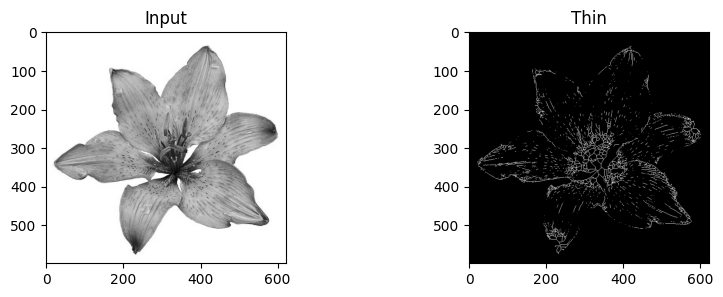

In [20]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

# Membaca gambar dan mengubahnya menjadi grayscale
image = img_as_float(
    color.rgb2gray(
        io.imread(
            '/content/drive/MyDrive/PVCK/Images/lily.jpg'
        )
    )
)

# Membuat citra biner
image_binary = image < 0.5

# Melakukan skeletonize
out_skeletonize = morphology.skeletonize(image_binary)

# Melakukan thinning
out_thin = morphology.thin(image_binary)

# Menampilkan hasil
f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')

plt.show()